# 02 · LP-VT transfer between datasets

**Question.** Which descriptors separate LP from VT in every system, and how much is lost when training on one system (source) and classifying on another (target)?

1. AUC of each descriptor by system (`transferibilidad_auc.csv`, `transferibilidad_ranking.csv`).
2. Source→target Gm matrices and summary by step (`transferencia_resumen_*.csv`).
3. An executable demonstration with the validation data.

The results include OVDAS systems (aggregated values only); the demonstration uses only `../datos/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})
pd.set_option("display.width", 160, "display.max_columns", 30)
DATOS, RES = Path("../datos"), Path("../resultados")

# English display names for the systems (the data files keep the Spanish names)
SYSTEM_EN = {"Hawái": "Hawai`i", "Norte de California": "Northern California",
             "Nevados de Chillan": "Nevados de Chillán", "Decepcion": "Deception Island",
             "Decepcion95": "Deception Island 1995", "Decepcion09": "Deception Island 2009",
             "Popocatepetl": "Popocatépetl"}

def en(df, cols=("sistema", "fuente", "destino")):
    """Replace system names by their English display names in the given columns."""
    df = df.copy()
    for c in cols:
        if c in df:
            df[c] = df[c].replace(SYSTEM_EN)
    return df

# English display names for the transfer steps (column escalon)
STEP_EN = {"0 diagonal": "0 diagonal", "1 estacion": "1 station",
           "2 misma agencia": "2 same agency", "3 entre agencias": "3 between agencies"}

## 1. LP-VT AUC by system and descriptor (fixed window)

In [2]:
auc = en(pd.read_csv(RES / "transferibilidad_auc.csv"))
rk = en(pd.read_csv(RES / "transferibilidad_ranking.csv"), cols=("sistema_min",))
rk_f = rk[rk.ventana == "fija"].sort_values("puntaje", ascending=False)
rk_f[["descriptor", "sentido", "auc_mediana", "iqr", "auc_min", "sistema_min", "invertidos"]].round(3)

,descriptor,sentido,auc_mediana,iqr,auc_min,sistema_min,invertidos
0,FI,LP<VT,0.929,0.066,0.730,Alaska,0
1,DET,LP>VT,0.874,0.089,0.554,Ruiz-Olleta,0
2,SR,LP<VT,0.868,0.086,0.652,Ruiz-Olleta,0
3,Lentr,LP>VT,0.741,0.094,0.403,Northern California,1
4,Wmax,LP<VT,0.724,0.083,0.406,Villarrica,1
5,Wdiv,LP>VT,0.724,0.083,0.406,Villarrica,1
6,LAM,LP>VT,0.764,0.139,0.454,Northern California,2
7,L,LP>VT,0.725,0.104,0.390,Northern California,1
8,fpeak,LP<VT,0.790,0.183,0.590,Hudson,0
9,W,LP>VT,0.701,0.132,0.583,Copahue,0


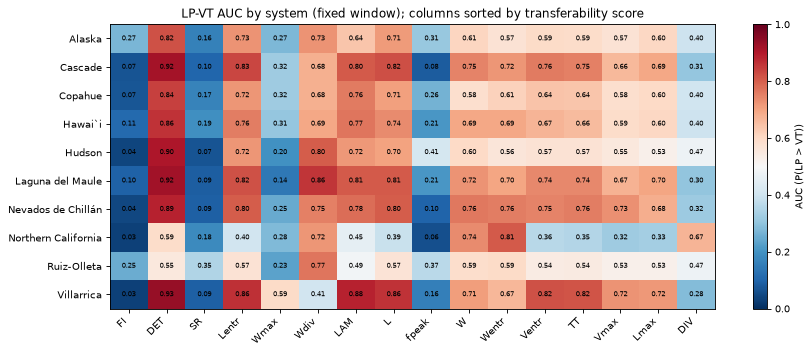

In [3]:
a = auc[auc.ventana == "fija"].pivot(index="sistema", columns="descriptor", values="auc")
a = a[rk_f.descriptor]
fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(a.values, cmap="RdBu_r", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(a.shape[1])); ax.set_xticklabels(a.columns, rotation=45, ha="right")
ax.set_yticks(range(a.shape[0])); ax.set_yticklabels(a.index)
for i in range(a.shape[0]):
    for j in range(a.shape[1]):
        ax.text(j, i, f"{a.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=ax, label="AUC (P(LP > VT))")
ax.set_title("LP-VT AUC by system (fixed window); columns sorted by transferability score")
fig.tight_layout()

## 2. Source→target matrices (M2, LP-VT, fixed window)

Gm = geometric mean of the LP and VT recalls, averaged over training draws of 100 events per class from the source. Scaling `fuente` (source statistics).

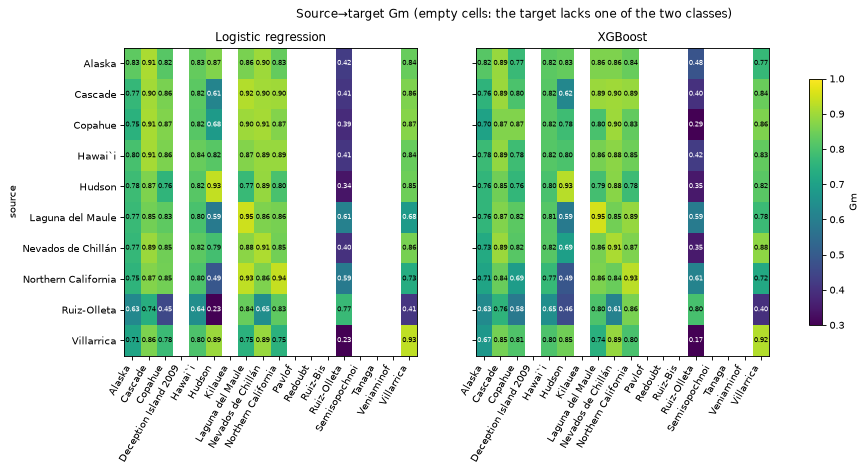

In [4]:
pares = en(pd.read_csv(RES / "transferencia_resumen_pares.csv"))
m2 = pares[(pares.matriz == "M2") & (pares.ventana == "fija") & (pares.escalado == "fuente")]
fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, mod in zip(ejes, ["log", "xgb"]):
    p = m2[m2.modelo == mod].pivot(index="fuente", columns="destino", values="gm")
    im = ax.imshow(p.values, cmap="viridis", vmin=0.3, vmax=1, aspect="auto")
    ax.set_xticks(range(p.shape[1])); ax.set_xticklabels(p.columns, rotation=60, ha="right")
    ax.set_yticks(range(p.shape[0])); ax.set_yticklabels(p.index)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            v = p.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                        color="w" if v < .7 else "k")
    ax.set_title({"log": "Logistic regression", "xgb": "XGBoost"}[mod])
ejes[0].set_ylabel("source"); fig.colorbar(im, ax=ejes, label="Gm", shrink=.8)
fig.suptitle("Source→target Gm (empty cells: the target lacks one of the two classes)");

Summary by step (diagonal, same agency, between agencies), M2:

In [5]:
esc = pd.read_csv(RES / "transferencia_resumen_escalones.csv")
esc["escalon"] = esc["escalon"].replace(STEP_EN)
esc[esc.matriz == "M2"].round(3)

,matriz,ventana,escalado,modelo,escalon,n_pares,gm_por_par,gm_por_fuente,gm_por_destino,perdida_por_par
24,M2,coda,fuente,log,0 diagonal,10,0.908,0.908,0.908,0.000
25,M2,coda,fuente,log,2 same agency,20,0.804,0.781,0.782,-0.122
26,M2,coda,fuente,log,3 between agencies,70,0.806,0.776,0.830,-0.083
27,M2,coda,fuente,xgb,0 diagonal,10,0.908,0.908,0.908,0.000
28,M2,coda,fuente,xgb,2 same agency,20,0.818,0.830,0.812,-0.068
29,M2,coda,fuente,xgb,3 between agencies,70,0.789,0.786,0.823,-0.085
30,M2,coda,sistema,log,0 diagonal,10,0.908,0.908,0.908,0.000
31,M2,coda,sistema,log,2 same agency,20,0.640,0.656,0.669,-0.272
32,M2,coda,sistema,log,3 between agencies,70,0.757,0.769,0.792,-0.117
33,M2,coda,sistema,xgb,0 diagonal,10,0.908,0.908,0.908,0.000


Single-class targets (the recall of that class is reported):

In [6]:
t1 = pd.read_csv(RES / "transferencia_resumen_una_clase.csv", header=[0, 1], index_col=0).round(3)
t1.rename(index=SYSTEM_EN)

ventana                 coda          fija       
modelo                   log    xgb    log    xgb
destino                                          
Deception Island 2009  0.993  0.994  0.994  0.992
Kilauea                0.760  0.732  0.744  0.746
Pavlof                 0.990  0.996  0.918  0.938
Redoubt                0.762  0.780  0.660  0.650
Ruiz-Bis               0.060  0.047  0.029  0.050
Semisopochnoi          0.975  0.974  0.968  0.961
Tanaga                 0.958  0.960  0.880  0.868
Veniaminof             0.996  0.996  0.991  0.983

## 3. Demonstration: train on Cascade, classify on other systems

Logistic regression (L2, standardization with the mean and standard deviation of the source) trained with 100 LP and 100 VT from Cascade, evaluated on the remaining Cascade events and on all LP and VT events from Hawai`i, Northern California and Alaska. Ten draws. This is a reduced version of the design in `transferencia.py` (without tuning of C and without XGBoost).

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score

F16 = ["DET", "L", "Lmax", "DIV", "Lentr", "LAM", "TT", "Vmax", "Ventr", "W",
       "Wmax", "Wdiv", "Wentr", "fpeak", "SR", "FI"]
d = en(pd.read_parquet(DATOS / "features16_fija.parquet"))
d = d[(d.motivo == "") & ~d.duplicado.fillna(False).astype(bool) & d.clase.isin(["LP", "VT"])]

def gm(y, p):
    r = recall_score(y, p, labels=["LP", "VT"], average=None)
    return np.sqrt(r[0] * r[1]), r[0], r[1]

FUENTE, DESTINOS = "Cascade", ["Hawai`i", "Northern California", "Alaska"]
src = d[d.sistema == FUENTE]
filas = []
for rep in range(10):
    tr = src.groupby("clase").sample(100, random_state=rep)
    resto = src.drop(tr.index)
    x = tr[F16].fillna(tr[F16].median())
    m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)).fit(x, tr.clase)
    for nombre, g in [(FUENTE + " (rest)", resto)] + [(s, d[d.sistema == s]) for s in DESTINOS]:
        xg = g[F16].fillna(tr[F16].median())
        filas.append((rep, nombre, *gm(g.clase, m.predict(xg))))
r = pd.DataFrame(filas, columns=["rep", "destino", "gm", "rec_LP", "rec_VT"])
r.groupby("destino")[["gm", "rec_LP", "rec_VT"]].agg(["mean", "std"]).round(3)

gm        rec_LP        rec_VT       
                      mean    std   mean    std   mean    std
destino                                                      
Alaska               0.800  0.018  0.800  0.032  0.800  0.020
Cascade (rest)       0.908  0.019  0.904  0.020  0.912  0.033
Hawai`i              0.826  0.013  0.835  0.012  0.818  0.032
Northern California  0.903  0.025  0.857  0.014  0.952  0.052

The loss relative to the diagonal (Cascade rest) measures what changing system costs without target labels; this is the starting point of the label-budget curve (notebook 03).